In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec


# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import IASFGK

# Setup toy problem

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

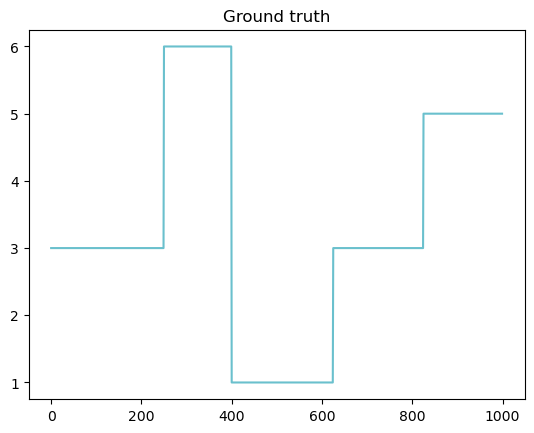

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

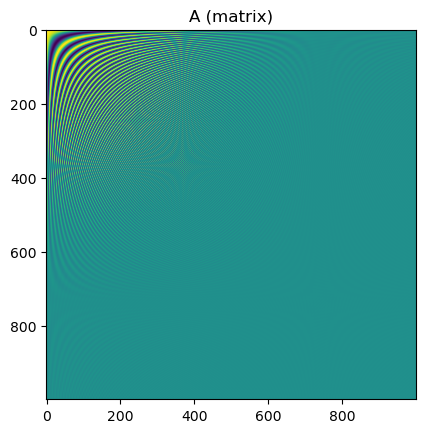

In [6]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [8]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[850:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

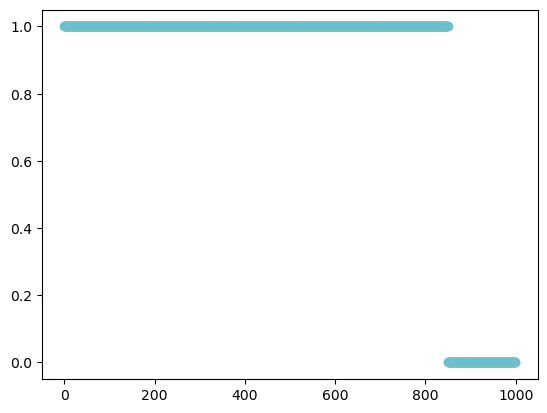

In [9]:
plt.scatter(grid, mask)
plt.show()

In [10]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

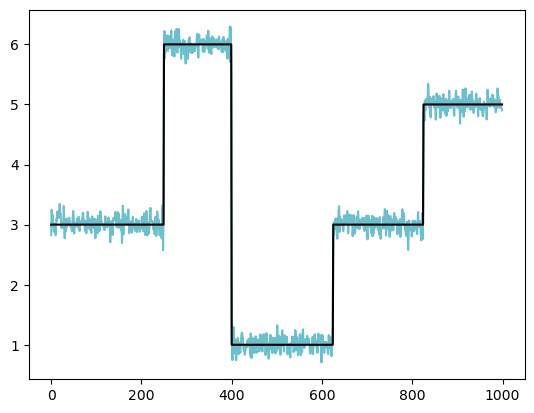

In [11]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [12]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)

#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-4
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasfk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# Run all methods

In [13]:
n_its = 200
method = "dp"

ksparsity = 15

# mmpdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
#                                                  regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params, 
#                                                  regparam_kwargs={"eta":1.01})

#print("Finished S-GKS (priorconditioned) (initial MMGKS solve)")

vpdata = gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=None, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished L2 GKS (priorconditioned)")

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=None, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)
print("Finished L2 GKS (vanilla)")

x0 = vdata["x"]
lambda0 = vdata["lambdah"]

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")


recpdata = iasgks_solver.solve_with_priorconditioning(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01}, dim_min=5, dim_max=15)
print("Finished S-GKS (priorconditioned, recycling)")


respdata = iasgks_solver.solve_with_priorconditioning(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01}, restart_dim=15)
print("Finished S-GKS (priorconditioned, restarted)")




data = iasgks_solver.solve(n_iter=n_its, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, ksparsity=ksparsity, xker=xker)
print("Finished S-GKS (vanilla)")

resdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, ksparsity=ksparsity, xker=xker, restart_dim=30)
print("Finished S-GKS (restarted)")


recdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=15, max_dim=30, ksparsity=ksparsity, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")


iasfkdata = iasfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FGK")

riasfkdata = iasfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FGK (refreshing)")


1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine_easier/../../msolver.py:784: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
17.611311349492393
44.96616401046227
59.73715612227503
69.12302720096545
77.82532481188835
82.23482246811106
85.29059694347588
87.67539774639546
89.55250228543193
90.49584445997507
91.37172106103243
91.9735875691276
92.38486353925246
92.66361686363149
92.87625370277875
93.00251075932148
93.07733589122523
93.11672477487349
93.14577933562171
93.1659490680399
93.17979388045126
93.188809431486
93.19422106091976
93.19786802061753
93.20078514077969
93.20214373921056
93.20305438847299
93.2036375686652
93.20399311798931
93.20417252222067
93.20428522146351
93.20435960538916
93.20439588497275
93.2044153584598
93.20442496767761
93.20443026300188
93.20443370844461
93.20443530068151
93.20443626553926
93.20443679563839
93.20443704544736
93.20443716423844
93.20443723072694
93.20443726101826
93.20443727753896
93.20443728552827
93.20443728926436
93.20443729104885
93.204437

537.2493094632935
285.1269878023372
111.34131543491141
96.66078033602365
94.01874347952433
93.39037864061936
93.23530223095574
93.20586496856787
93.20449269478554
93.20470704474323
93.20494572469659
93.20472652833938
93.20451263604834
93.20445024115533
93.20443234157439
93.2044369860529
93.2044366699034
93.20443670626008
93.20443693593369
93.20443710739094
93.20443721940977
93.20443729346724
93.20443730823656
93.20443729535519
93.20443729336903
93.20443729350706
93.20443729277417
93.20443729256546
93.20443729246486
93.2044372924997
93.20443729253064
93.20443729253533
93.20443729253417
93.20443729253196
93.20443729253451
93.20443729253516
93.204437292535
93.2044372925342
93.2044372925343
93.20443729253357
93.20443729253375
93.20443729253373
93.20443729253513
93.20443729253533
93.20443729253448
93.2044372925355
93.20443729253338
93.20443729253343
93.20443729253464
93.20443729253375
93.20443729253526
93.20443729253614
93.20443729253532
93.20443729253508
93.20443729253417
93.20443729253346

1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
9.765755418887137
148.48749456869083
1525.5952460387996
36480.072526465345
2532733.419921566
1e-07
23.16442249368805
502.9505064601222
10338.587243942868
721629.9229742604
10000000.0
1e-07
24.25715693234155
483.5982560909153
8862.508818651731
555928.96143755
10000000.0
1e-07
28.551209862227232
488.4998890675004
8080.376913563723
446561.81530829595
10000000.0
1e-07
31.516300063498104
516.354506541299
10926.688396353917
733455.4860181062
10000000.0
1e-07
34.48313797655174
522.0525089071008
10700.749872104387
716375.8829347115
10000000.0
1e-07
36.31265804693015
529.4907352349657
10833.760529800516
721440.182401586
10000000.0
1e-07
36.74474713603698
527.9844566512866
10789.708417632726
713885.6693955966
10000000.0
1e-07
37.07114653039743
529.382294575401
10836.227502600232
717127.1730785106
10000000.0
1e-07
37.18899162886922
529.3203287102389
10833.339984215514
716323.8992000801
10000000.0
1e-07
37.22086469493408
529.2352921589693
10831

1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
9.765755418887137
148.48749456869083
1525.5952460387996
36480.072526465345
2532733.419921566
1e-07
23.16442249368805
502.9505064601222
10338.587243942868
721629.9229742604
10000000.0
1e-07
24.25715693234155
483.5982560909153
8862.508818651731
555928.96143755
10000000.0
1e-07
28.551209862227232
488.4998890675004
8080.376913563723
446561.81530829595
10000000.0
1e-07
31.516300063498104
516.354506541299
10926.688396353917
733455.4860181062
10000000.0
1e-07
34.48313797655174
522.0525089071008
10700.749872104387
716375.8829347115
10000000.0
1e-07
36.31265804693015
529.4907352349657
10833.760529800516
721440.182401586
10000000.0
1e-07
36.74474713603698
527.9844566512866
10789.708417632726
713885.6693955966
10000000.0
1e-07
37.07114653039743
529.382294575401
10836.227502600232
717127.1730785106
10000000.0
1e-07
37.18899162886922
529.3203287102389
10833.339984215514
716323.8992000801
10000000.0
1e-07
37.22086469493408
529.2352921589693
10831

1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
9.765755418887137
1e-07
9.785615000891218
1e-07
38.93626050488148
1e-07
23.285893006945784
1e-07
15.80947919760017
1e-07
15.414637527951104
1e-07
17.194171341958576
1e-07
17.453336439469396
1e-07
17.45060715450722
1e-07
47.24034573732835
1e-07
31.095641415110023
1e-07
22.549761603673616
1e-07
22.37956792788147
1e-07
22.223630307555148
1e-07
26.355285236784443
1e-07
26.35472722585193
1e-07
53.58548983024719
1e-07
36.217932128803426
1e-07
27.167300300781722
1e-07
26.413577883932142
1e-07
27.652792433236208
1e-07
24.866009720384792
1e-07
24.866102536600895
1e-07
38.83588364818485
1e-07
30.43732791474938
1e-07
25.765006695037634
1e-07
29.899458634491133
1e-07
30.73666316345258
1e-07
30.761213924989377
1e-07
30.76104894989874
1e-07
51.599555160367615
1e-07
37.040906208889375
1e-07
32.04623307600674
1e-07
30.89901191840329
1e-07
31.00863342070656
1e-07
28.06689127255674
1e-07
28.06698247096513
1e-07
36.18835563660582
1e-07
29.858639834493

57.815069702979294
2531.531647104239
22084.695658774697
73931.14178941527
165214.1617026226
286042.57069679577
409735.02581239725
488927.41979192675
431849.37654959457
178565.4038951652
19220.379822838164
6221.178798417505
3833.8762059970013
4229.988123636587
7547.599813388282
15805.01340001751
33671.97024630946
68267.9838692012
101514.35630631814
133877.03525581828
169658.3103508102
200156.8850612671
220618.36217938398
205220.8620101702
163307.4483013246
119884.65342390041
84224.68230542704
58330.418907742845
41329.72997775698
28221.116318144777
20116.19713851297
15554.757392391539
11174.607871746202
7761.1192152618605
5848.292621010105
4684.015962393224
4406.594323498368
4374.475797090839
4334.701596567115
4219.394055800808
3969.151225946157
3545.0918014280146
3137.627681161484
2782.6649652402525
2522.3254776009976
2319.4429261029086
2168.031017869398
2115.6434169376994
2089.0755683696216
2086.1581592534544
2090.0421918991688
2093.0023014817934
2093.968675436723
2094.185043808489
209

57.815069702979294
2531.531647104239
22084.695658774697
73931.14178941527
165214.1617026226
286042.57069679577
409735.02581239725
488927.41979192675
431849.37654959457
178565.4038951652
19220.379822838164
6221.178798417505
3833.8762059970013
4229.988123636587
7547.599813388282
15805.01340001751
33671.97024630946
68267.9838692012
101514.35630631814
133877.03525581828
169658.3103508102
200156.8850612671
220618.36217938398
205220.8620101702
191466.0465321674
175234.6726562727
137660.37039664897
61470.74513465414
19403.034317257334
64910.33194826974
58221.17491246783
18346.968374107255
58342.64836384659
20928.659092138947
26857.22860067248
21073.47789184437
15886.405776747737
14953.408043457252
9895.122311286355
9260.837891895013
7120.909402158573
6267.292210050484
5293.295462329534
5063.394784037191
4617.399802300304
4597.308588702948
4298.80738357706
4256.812063652212
3928.64247285156
3782.2801718647356
3565.3807715521716
3414.1716805492542
3231.0307570435602
3165.218914829341
3072.80432

57.815069702979294
2531.531647104239
22084.695658774697
73931.14178941527
165214.1617026226
286042.57069679577
409735.02581239725
488927.41979192675
431849.37654959457
178565.4038951652
19220.379822838164
6221.178798417505
3833.8762059970013
4229.988123636587
7547.599813388282
15805.01340001751
33671.97024630946
68267.9838692012
101514.35630631814
133877.03525581828
169658.3103508102
200156.8850612671
220618.36217938398
205220.8620101702
(30, 30)
(30, 30)
(60, 30)
201482.11887860333
164447.24054902294
102026.7406730735
33416.23822591736
56406.28284183167
16622.51995871669
60231.717634763845
85153.61666709873
25945.95157668928
20856.34439170381
20453.94231381857
14714.673303542637
13243.665563841489
10309.073797463003
8205.498632386538
(30, 30)
(30, 30)
(60, 30)
12866.090217649966
4632.592999783604
11886.059840761527
11912.542951190488
16874.690108281622
32263.08830063824
71983.82002126794
102217.87166500337
155409.45554620834
277123.8385901062
437959.6995878565
613063.4600629426
833759

# Make plots

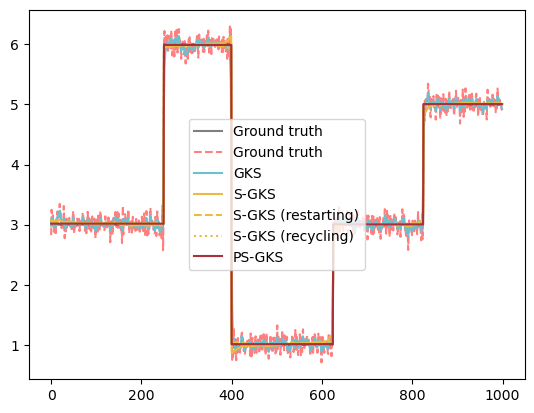

In [14]:
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.5)
plt.plot(A.T @ b, label="Ground truth", color="red", alpha=0.5, ls="--")
plt.plot(vdata["x"], label="GKS", color="C0")
plt.plot(data["x"], label="S-GKS", color="C1")
plt.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["x"], label="PS-GKS", color="C2")
plt.legend()
plt.show()

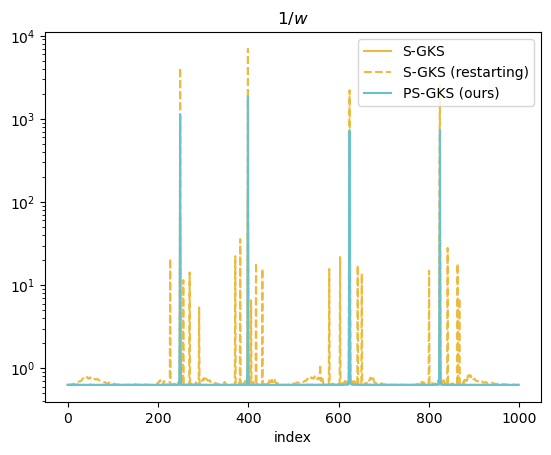

In [15]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(1.0/data['w'], label="S-GKS", color="C1")
plt.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
#plt.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(1.0/pdata['w'], label="PS-GKS (ours)")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

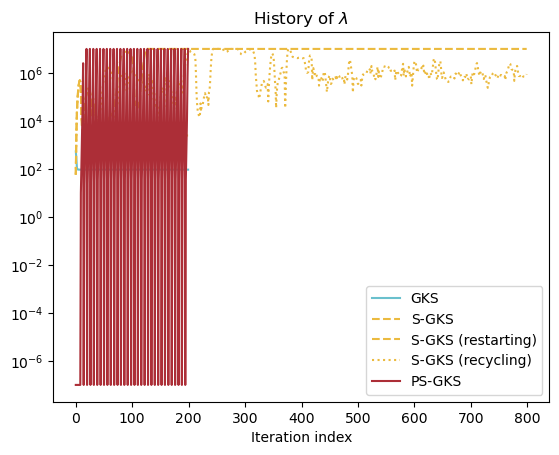

In [16]:
plt.semilogy(vdata["lambda_history"], label="GKS", color="C0")
plt.semilogy(data["lambda_history"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

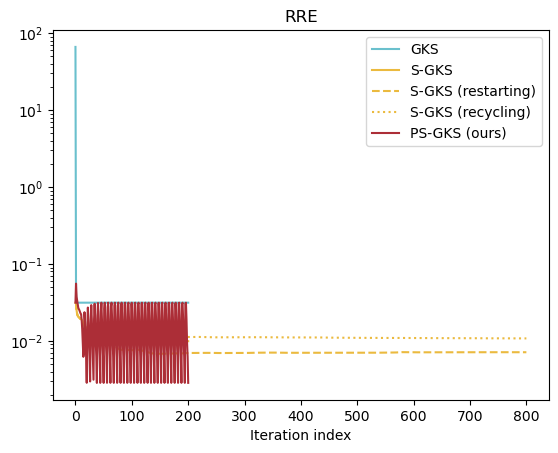

In [17]:
plt.semilogy(vdata["rre_history"], label="GKS", color="C0")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

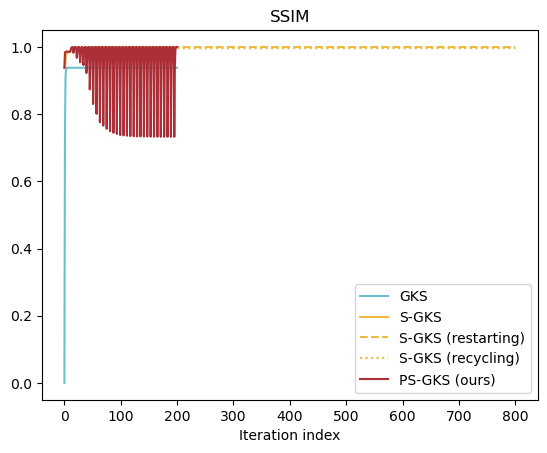

In [18]:
plt.plot(vdata["ssim_history"], label="GKS", color="C0")
plt.plot(data["ssim_history"], label="S-GKS", color="C1")
plt.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C2")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

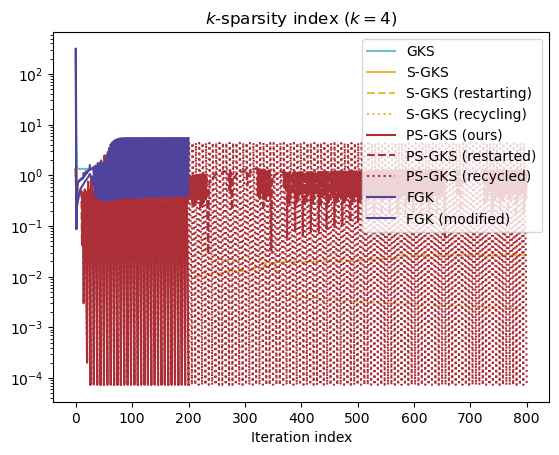

In [19]:
plt.semilogy(vdata["ksparsity_indices"], label="GKS", color="C0")
plt.semilogy(data["ksparsity_indices"], label="S-GKS", color="C1")
plt.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["ksparsity_indices"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ksparsity_indices"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ksparsity_indices"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(iasfkdata["ksparsity_indices"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(riasfkdata["ksparsity_indices"], label="FGK (modified)", alpha=1.0, color="C7")
plt.title("$k$-sparsity index ($k = 4$)")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

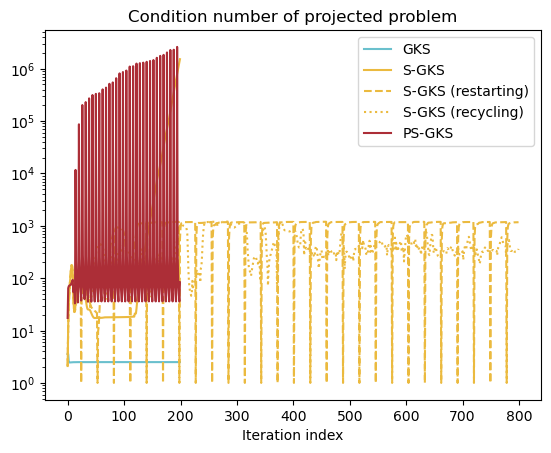

In [20]:
plt.semilogy(vdata["cond_ests"], label="GKS", color="C0")
plt.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
plt.title("Condition number of projected problem")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots in the paper

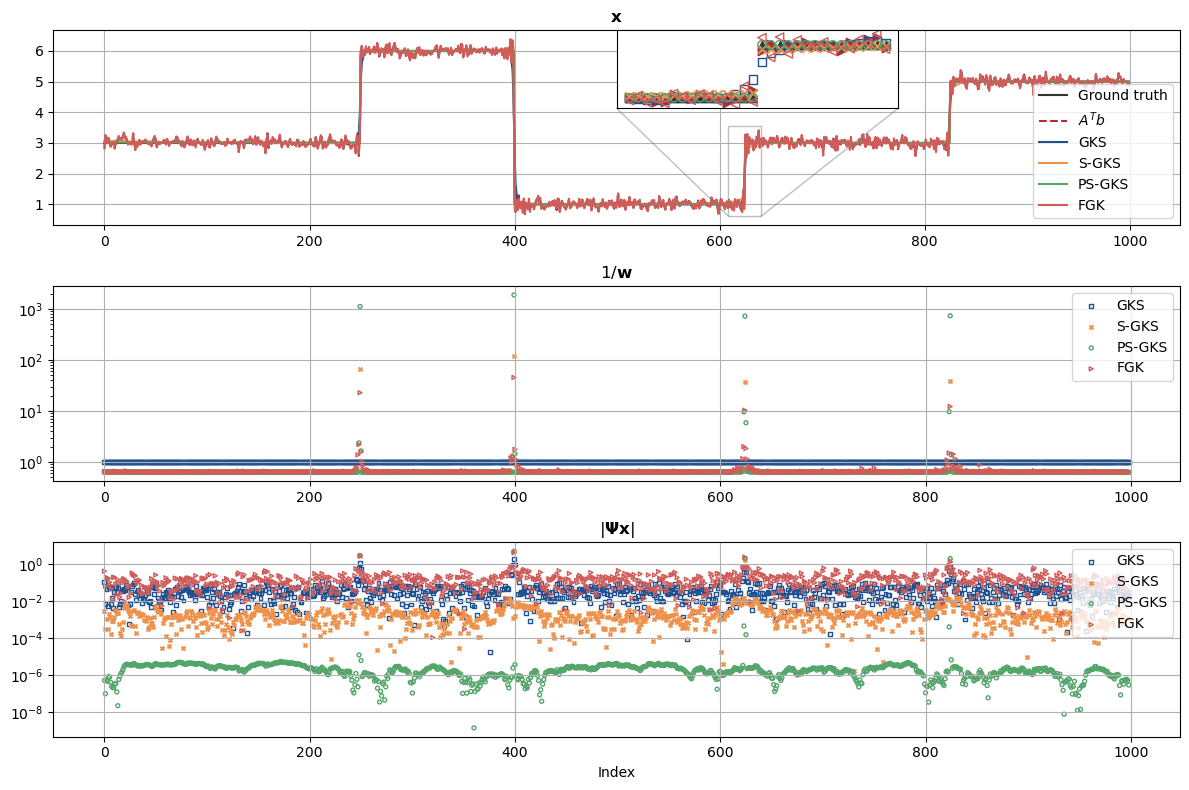

In [27]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(3, 1, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0])
ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
#ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
#ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
ax1.plot([i for i in range(len(data["x"]))], iasfkdata["x"], label="FGK", color="C6")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], iasfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")
inset_ax.grid()

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
#ax1.set_xlabel("Index")
ax1.set_title('$\\mathbf{x}$')
ax1.grid()


ax2 = fig.add_subplot(gs[1])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/iasfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax2.set_title("$1/\\mathbf{w}$")
#ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid()





ax10 = fig.add_subplot(gs[2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ iasfkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax10.set_title("$| \\boldsymbol{\Psi} \mathbf{x} |$")
ax10.set_xlabel("Index")
ax10.set_yscale("log")
ax10.legend(loc="upper right")
ax10.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_ias_reconstructions.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_ias_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


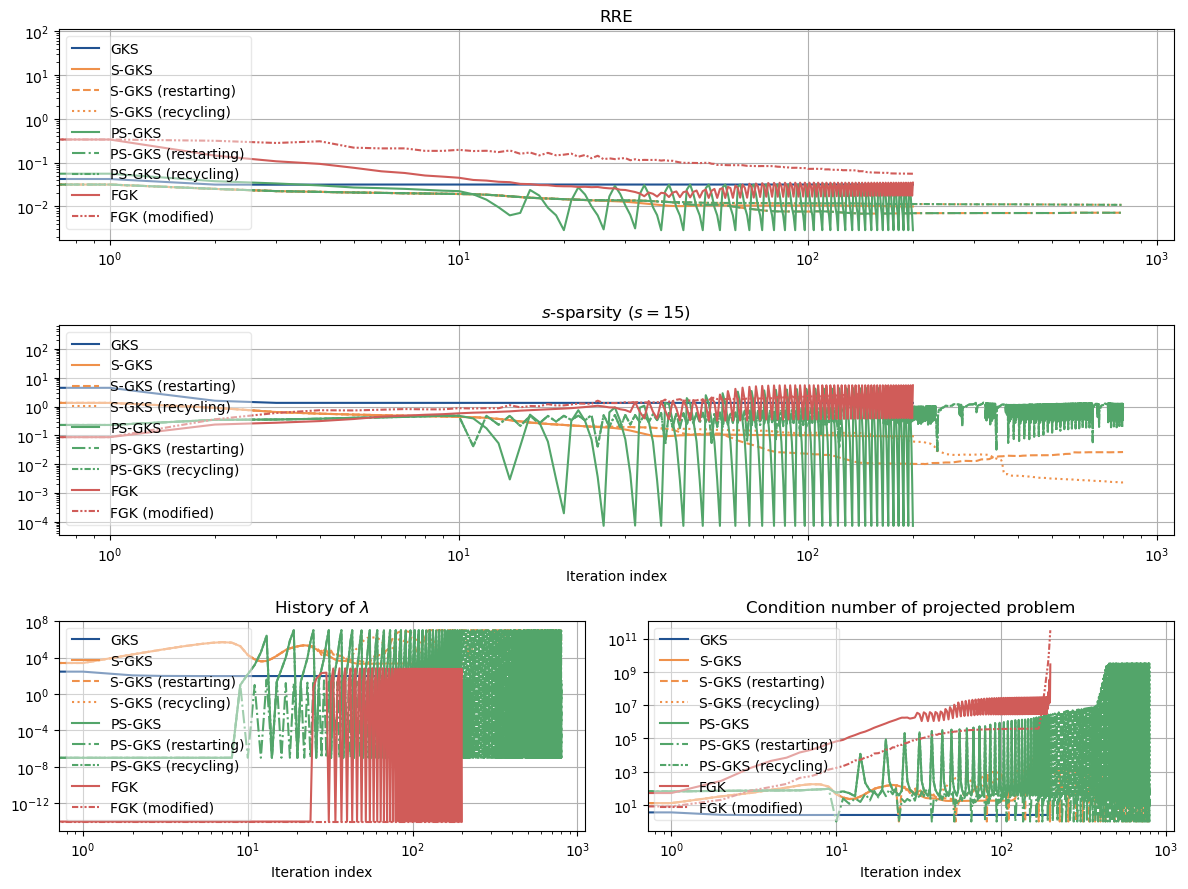

In [22]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 9))
gs = gridspec.GridSpec(3, 2, figure=fig)


ax3 = fig.add_subplot(gs[0,:])
ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax3.semilogy(iasfkdata["rre_history"], label="FGK", color="C6")
ax3.semilogy(riasfkdata["rre_history"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
#ax3.set_xscale("log")
ax3.set_title("RRE")
#ax3.set_xlabel("Iteration index")
ax3.set_xscale("log")
ax3.legend(loc="upper right")
ax3.legend().get_frame().set_alpha(0.45)
ax3.grid()




ax4 = fig.add_subplot(gs[2,0])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax4.semilogy(iasfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
ax4.semilogy(riasfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend(loc="upper left").get_frame().set_alpha(0.45)
#ax4.legend().get_frame().set_alpha(0.45)
ax4.set_xscale("log")
ax4.grid()



ax6 = fig.add_subplot(gs[1,:])
ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax6.semilogy(iasfkdata["ksparsity_indices"], label="FGK", color="C6")
ax6.semilogy(riasfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax6.set_title("$s$-sparsity ($s = 15$)")
ax6.set_xlabel("Iteration index")
#ax6.set_xlim(None, 10**3)
ax6.set_xscale("log")
ax6.legend(loc="upper right")
ax6.legend(loc="upper left").get_frame().set_alpha(0.45)
ax6.grid()


ax5 = fig.add_subplot(gs[2, 1])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax5.semilogy(iasfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
ax5.semilogy(riasfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.legend(loc="upper left").get_frame().set_alpha(0.45)
ax5.set_xscale("log")
ax5.grid()

# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_ias_performance.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_ias_performance.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


In [23]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 8))
# gs = gridspec.GridSpec(3, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS (ours)", color="C4")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :2])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()


# ax4 = fig.add_subplot(gs[1, 2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()



# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, 0])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend()



# ax6 = fig.add_subplot(gs[2, 1])
# ax6.plot(vdata["ssim_history"], label="GKS", color="C3")
# ax6.plot(data["ssim_history"], label="S-GKS", color="C5")
# ax6.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("SSIM")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[2, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# fig.savefig("1d_cosine_example_ias.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_ias.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


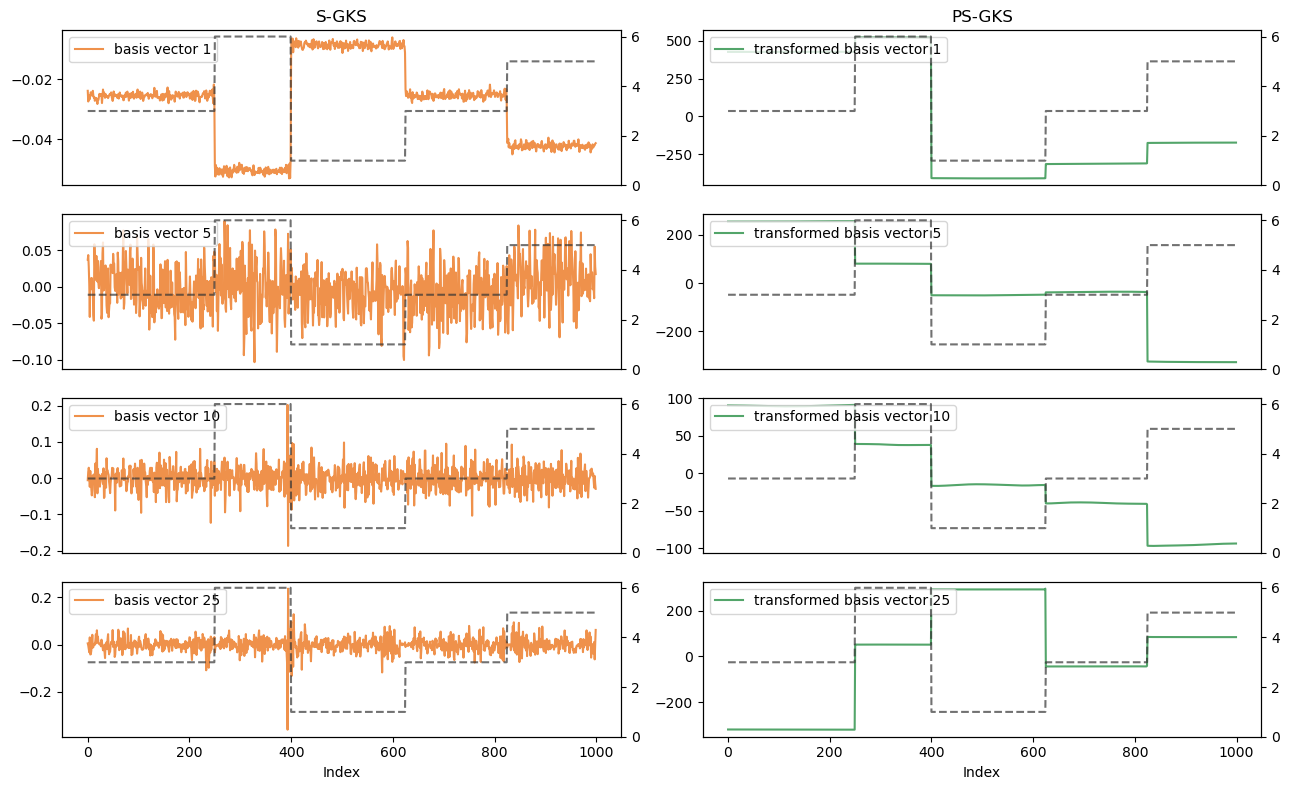

In [24]:
fig, axs = plt.subplots(4,2, figsize=(13,8))

loc = "upper left"

kk = 0
axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[0,0].legend(loc=loc)
axs[0,0].set_xticks([])
axs[0,0].set_title("S-GKS")
axst = axs[0,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[1,0].legend(loc=loc)
axs[1,0].set_xticks([])
axst = axs[1,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[2,0].legend(loc=loc)
axs[2,0].set_xticks([])
axst = axs[2,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[3,0].legend(loc=loc)
axs[3,0].set_xlabel("Index")
axst = axs[3,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])




kk = 0
axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[0,1].legend(loc=loc)
axs[0,1].set_xticks([])
axs[0,1].set_title("PS-GKS")
axst = axs[0,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[1,1].legend(loc=loc)
axs[1,1].set_xticks([])
axst = axs[1,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[2,1].legend(loc=loc)
axs[2,1].set_xticks([])
axst = axs[2,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[3,1].legend(loc=loc)
axs[3,1].set_xlabel("Index")
axst = axs[3,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

fig.tight_layout()
fig.savefig("1d_cosine_example_basis_vectors_ias.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors_ias.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()